In [17]:
import os
import numpy as np
import scipy.stats as stats
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from dynamic_routing_analysis import decoding_utils
# import dynamic_routing_analysis as dra
# import npc_lims

import matplotlib
import matplotlib.font_manager as fm

matplotlib.rcParams['font.size'] = 8
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fm.FontProperties().set_family('arial')

%load_ext autoreload
%autoreload 2
%matplotlib inline
# %matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
results_path_context_module = "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_decode_context_50_units_context_module_train_on_correct_trials_0/"

results_path = "s3://aind-scratch-data/dynamic-routing/decoding/results/baseline_context_500ms_leave_2_blocks_out_half_block_shifts_10_units_strict_drift_0/" #v289

In [4]:
session_table_path=r"\\allen\programs\mindscope\workgroups\dynamicrouting\Ethan\CO decoding results\session_table_v0.289.parquet"


session_table=pl.read_parquet(session_table_path)

dr_session_list=(
    session_table.filter(
    pl.col('project')=="DynamicRouting",
    # pl.col('project')=="Templeton",
    pl.col('is_production'),
    pl.col('is_annotated'),
    pl.col('issues')==[],
    pl.col('is_opto_perturbation').eq(False),
    pl.col('is_injection_perturbation').eq(False),
    pl.col('is_context_naive').eq(False),
    # pl.col('is_good_behavior').eq(True),
    # pl.col('is_engaged').eq(True),
    )['session_id'].to_list()
    )

block_dprime_threshold=1.0

good_behavior_table={
    'session_id':[],
    'n_good_vis_blocks':[],
    'n_good_aud_blocks':[],
    'n_engaged_blocks':[],
}

for sel_session in dr_session_list:
    n_good_vis_blocks=np.sum(session_table.filter(pl.col('session_id') == sel_session)['cross_modality_dprime_vis_blocks'].to_numpy()[0]>=block_dprime_threshold)
    n_good_aud_blocks=np.sum(session_table.filter(pl.col('session_id') == sel_session)['cross_modality_dprime_aud_blocks'].to_numpy()[0]>=block_dprime_threshold)
    good_behavior_table['session_id'].append(sel_session)
    good_behavior_table['n_good_vis_blocks'].append(n_good_vis_blocks)
    good_behavior_table['n_good_aud_blocks'].append(n_good_aud_blocks)
    n_engaged_blocks=np.sum(session_table.filter(pl.col('session_id') == sel_session)['n_contingent_rewards'].to_numpy()[0]>=10)
    good_behavior_table['n_engaged_blocks'].append(n_engaged_blocks)

good_behavior_table=pd.DataFrame(good_behavior_table)
dr_session_list=good_behavior_table.query('n_good_vis_blocks>=2 and n_good_aud_blocks>=2 and n_engaged_blocks>=4')['session_id'].values

In [5]:
# load all sessions
predict_proba_pd = decoding_utils.load_session_wise_decoder_confidence(
        results_path, dr_session_list,).to_pandas()

predict_proba_context_module_pd = decoding_utils.load_session_wise_decoder_confidence(
        results_path_context_module, dr_session_list,).to_pandas()

C:\Users\ethan.mcbride\Code\dynamic_routing_analysis\src\dynamic_routing_analysis\decoding_utils.py:2201: PerformanceWarning: checking membership of a LazyFrame using `in` requires resolving its schema, which is a potentially expensive operation. Use `key in LazyFrame.collect_schema()` to check membership without this warning.
  if 'labels' in col_names:
C:\Users\ethan.mcbride\Code\dynamic_routing_analysis\src\dynamic_routing_analysis\decoding_utils.py:2225: PerformanceWarning: checking membership of a LazyFrame using `in` requires resolving its schema, which is a potentially expensive operation. Use `key in LazyFrame.collect_schema()` to check membership without this warning.
  if 'decision_function' in col_names:
C:\Users\ethan.mcbride\Code\dynamic_routing_analysis\src\dynamic_routing_analysis\decoding_utils.py:2201: PerformanceWarning: checking membership of a LazyFrame using `in` requires resolving its schema, which is a potentially expensive operation. Use `key in LazyFrame.collec

In [20]:
# build table of predict_proba aligned to block switches

sel_predict_proba_pd=predict_proba_context_module_pd  # or predict_proba_context_module_pd
sel_unit_subsample_size=None  # None -> first available
sel_time_aligned_to='stim_start_time'
sel_bin_center=None  # None -> first available
trials_rel_to_switch=np.arange(-10,21)
min_dprime=1.0  # e.g. 1.0 to require good blocks before and after the switch

if sel_bin_center is None:
    sel_bin_center=sel_predict_proba_pd['bin_center'].unique()[0]
switch_input_pd=sel_predict_proba_pd.query('bin_center==@sel_bin_center').copy()

context_switch_table_df=decoding_utils.get_context_switch_table(
    switch_input_pd,
    session_list=dr_session_list,
    sel_unit_subsample_size=sel_unit_subsample_size,
    sel_time_aligned_to=sel_time_aligned_to,
    trials_rel_to_switch=trials_rel_to_switch,
)
# single time bin -> scalar per trial
context_switch_table_df['predict_proba']=context_switch_table_df['predict_proba'].apply(lambda x: x[0])

context_switch_table_df['subject_id']=context_switch_table_df['session_id'].str.split('_').str[0]
# is_vis_rewarded and is_contingent_switch refer to the first trial of the new block
context_switch_table_df['switch_direction']=np.where(context_switch_table_df['is_vis_rewarded'],'aud_to_vis','vis_to_aud')

# flip the whole window (1 - p) for switches into aud blocks -> p(new block context)
context_switch_table_df['predict_proba_flipped']=np.where(
    context_switch_table_df['switch_direction']=='vis_to_aud',
    1-context_switch_table_df['predict_proba'],
    context_switch_table_df['predict_proba'],
)

if min_dprime is not None:
    context_switch_table_df=context_switch_table_df.query('dprime_before_switch>=@min_dprime and dprime_after_switch>=@min_dprime')

# number of switches of each type (counted once per switch, not per structure)
(context_switch_table_df
    .drop_duplicates(['session_id','switch_index_in_session'])
    .groupby(['switch_direction','is_contingent_switch'])
    .agg(n_switches=('session_id','size'), n_sessions=('session_id','nunique'), n_subjects=('subject_id','nunique')))

n_switches  n_sessions  n_subjects
switch_direction is_contingent_switch                                    
aud_to_vis       False                         78          53          27
                 True                          79          51          25
vis_to_aud       False                         91          59          28
                 True                          72          49          30

In [21]:
switch_direction_colors={'vis_to_aud':'tab:blue','aud_to_vis':'tab:green'}
switch_direction_labels={'vis_to_aud':'V->A','aud_to_vis':'A->V'}


def get_subject_avg(df, value_col):
    # average switches within session, then sessions within subject
    session_avg=df.groupby(['subject_id','session_id','trial_rel_to_switch'])[value_col].mean().reset_index()
    subject_avg=session_avg.groupby(['subject_id','trial_rel_to_switch'])[value_col].mean().reset_index()
    return subject_avg


def plot_mean_sem_across_subjects(ax, subject_avg, value_col, color, label):
    subject_stats=subject_avg.groupby('trial_rel_to_switch')[value_col].agg(['mean','sem']).reset_index()
    ax.plot(subject_stats['trial_rel_to_switch'], subject_stats['mean'], color=color, label=label, marker='.', markersize=3, linewidth=1)
    ax.fill_between(subject_stats['trial_rel_to_switch'],
                    subject_stats['mean']-subject_stats['sem'],
                    subject_stats['mean']+subject_stats['sem'],
                    color=color, alpha=0.2, linewidth=0)

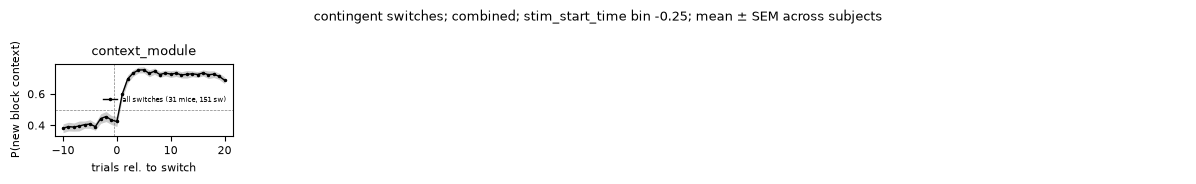

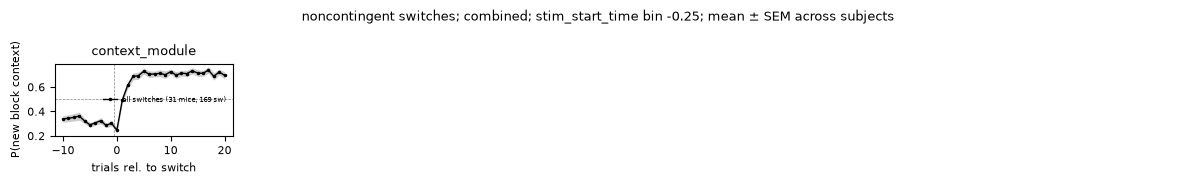

In [22]:
# plot switch-aligned predict_proba per structure, separately for contingent / noncontingent switches
# error bars: mean +/- SEM across subjects

split_by_switch_direction=False  # True: V->A and A->V separately (raw p(vis)); False: combined, switches into aud blocks flipped (1-p) -> p(new block context)
sel_structures=None  # None -> all structures with >= min_n_subjects
min_n_subjects=3
n_cols=6

savefigs=False
savepath=r""

if split_by_switch_direction:
    value_col='predict_proba'
    ylabel='P(vis context)'
    direction_groups=['vis_to_aud','aud_to_vis']
else:
    value_col='predict_proba_flipped'
    ylabel='P(new block context)'
    direction_groups=[None]

if sel_structures is None:
    n_subjects_per_structure=context_switch_table_df.groupby('structure')['subject_id'].nunique()
    plot_structures=sorted(n_subjects_per_structure[n_subjects_per_structure>=min_n_subjects].index)
    if 'context_module' in plot_structures:
        plot_structures.remove('context_module')
        plot_structures.insert(0,'context_module')
else:
    plot_structures=list(sel_structures)

n_rows=int(np.ceil(len(plot_structures)/n_cols))
plot_mode='split' if split_by_switch_direction else 'combined'

for sel_is_contingent_switch in [True,False]:
    switch_type='contingent' if sel_is_contingent_switch else 'noncontingent'
    condition_df=context_switch_table_df.query('is_contingent_switch==@sel_is_contingent_switch')

    fig,ax=plt.subplots(n_rows,n_cols,figsize=(n_cols*2,n_rows*1.8),sharex=True,sharey=True,squeeze=False)
    ax=ax.flatten()

    for xx,sel_structure in enumerate(plot_structures):
        structure_df=condition_df.query('structure==@sel_structure')
        ax[xx].axhline(0.5,color='grey',linestyle='--',linewidth=0.5)
        ax[xx].axvline(-0.5,color='grey',linestyle='--',linewidth=0.5)

        for switch_direction in direction_groups:
            if switch_direction is None:
                direction_df=structure_df
                color='k'
                label='all switches'
            else:
                direction_df=structure_df.query('switch_direction==@switch_direction')
                color=switch_direction_colors[switch_direction]
                label=switch_direction_labels[switch_direction]
            if len(direction_df)==0:
                continue
            n_subjects=direction_df['subject_id'].nunique()
            n_switches=direction_df[['session_id','switch_index_in_session']].drop_duplicates().shape[0]
            plot_mean_sem_across_subjects(
                ax[xx], get_subject_avg(direction_df, value_col), value_col,
                color, f'{label} ({n_subjects} mice, {n_switches} sw)')

        ax[xx].set_title(sel_structure)
        ax[xx].legend(fontsize=5, frameon=False)

    for xx in range(len(plot_structures),len(ax)):
        ax[xx].axis('off')
    for xx in range(0,len(ax),n_cols):
        ax[xx].set_ylabel(ylabel)
    for xx in range(max(len(plot_structures)-n_cols,0),len(plot_structures)):
        ax[xx].set_xlabel('trials rel. to switch')
        ax[xx].xaxis.set_tick_params(labelbottom=True)

    fig.suptitle(f"{switch_type} switches; {plot_mode}; {sel_time_aligned_to} bin {sel_bin_center}; mean ± SEM across subjects")
    fig.tight_layout()

    if savefigs:
        fig.savefig(os.path.join(savepath,f"switch_aligned_predict_proba_{switch_type}_{plot_mode}.png"),dpi=300,bbox_inches='tight')
        fig.savefig(os.path.join(savepath,f"switch_aligned_predict_proba_{switch_type}_{plot_mode}.pdf"),bbox_inches='tight')

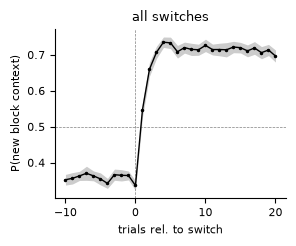

In [24]:
# overlay switch-aligned P(new block context) for selected structures, one color per structure
# error bars: mean +/- SEM across subjects

# sel_structures=['ACAd','MOs','SSp','SCm','MRN','CP','VISp']
sel_structures=['context_module']
combine_switch_types=True  # True: pool contingent + noncontingent switches in one panel; False: separate panels

savefigs=False
savepath=r""

value_col='predict_proba_flipped'
ylabel='P(new block context)'
if len(sel_structures) == 1:
    structure_colors={sel_structures[0]:'k'}
else:
    structure_colors={sel_structure:plt.cm.tab10(xx%10) for xx,sel_structure in enumerate(sel_structures)}

if combine_switch_types:
    switch_type_groups={'all':[True,False]}
else:
    switch_type_groups={'contingent':[True],'noncontingent':[False]}

fig,ax=plt.subplots(1,len(switch_type_groups),figsize=(3*len(switch_type_groups),2.5),sharex=True,sharey=True,squeeze=False)
ax=ax.flatten()

for xx,(switch_type,is_contingent_values) in enumerate(switch_type_groups.items()):
    condition_df=context_switch_table_df.query('is_contingent_switch in @is_contingent_values')
    ax[xx].axhline(0.5,color='grey',linestyle='--',linewidth=0.5)
    ax[xx].axvline(0,color='grey',linestyle='--',linewidth=0.5)

    for sel_structure in sel_structures:
        structure_df=condition_df.query('structure==@sel_structure')
        if len(structure_df)==0:
            continue
        n_subjects=structure_df['subject_id'].nunique()
        n_switches=structure_df[['session_id','switch_index_in_session']].drop_duplicates().shape[0]
        plot_mean_sem_across_subjects(
            ax[xx], get_subject_avg(structure_df, value_col), value_col,
            structure_colors[sel_structure], f'{sel_structure} ({n_subjects} mice, {n_switches} sw)')

    ax[xx].set_title(f'{switch_type} switches')
    ax[xx].set_xlabel('trials rel. to switch')
    if len(sel_structures)>1:
        ax[xx].legend(fontsize=5, frameon=False)
    
    ax[xx].spines['top'].set_visible(False)
    ax[xx].spines['right'].set_visible(False)
ax[0].set_ylabel(ylabel)


plot_mode='switch_types_combined' if combine_switch_types else 'switch_types_split'
# fig.suptitle(f"{sel_time_aligned_to} bin {sel_bin_center}; mean ± SEM across subjects")
fig.tight_layout()

if savefigs:
    fig.savefig(os.path.join(savepath,f"switch_aligned_predict_proba_structure_overlay_{plot_mode}.png"),dpi=300,bbox_inches='tight')
    fig.savefig(os.path.join(savepath,f"switch_aligned_predict_proba_structure_overlay_{plot_mode}.pdf"),bbox_inches='tight')

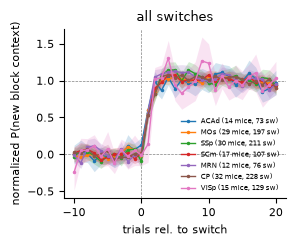

In [19]:
# same as above, but each area normalized to 0 (pre-switch steady state) -> 1 (post-switch steady state)
# normalization uses the across-subject mean trace of each area, and the same linear transform is applied
# to every subject's trace, so SEM is scaled consistently
# error bars: mean +/- SEM across subjects

sel_structures=['ACAd','MOs','SSp','SCm','MRN','CP','VISp']
combine_switch_types=True  # True: pool contingent + noncontingent switches in one panel; False: separate panels
pre_switch_window=(-10,-1)  # inclusive trial range for pre-switch steady state -> 0
post_switch_window=(10,20)  # inclusive trial range for post-switch steady state -> 1

savefigs=False
savepath=r""

value_col='predict_proba_flipped'
norm_col='predict_proba_norm'
structure_colors={sel_structure:plt.cm.tab10(xx%10) for xx,sel_structure in enumerate(sel_structures)}

if combine_switch_types:
    switch_type_groups={'all':[True,False]}
else:
    switch_type_groups={'contingent':[True],'noncontingent':[False]}

fig,ax=plt.subplots(1,len(switch_type_groups),figsize=(3*len(switch_type_groups),2.5),sharex=True,sharey=True,squeeze=False)
ax=ax.flatten()

for xx,(switch_type,is_contingent_values) in enumerate(switch_type_groups.items()):
    condition_df=context_switch_table_df.query('is_contingent_switch in @is_contingent_values')
    ax[xx].axhline(0,color='grey',linestyle='--',linewidth=0.5)
    ax[xx].axhline(1,color='grey',linestyle='--',linewidth=0.5)
    ax[xx].axvline(0,color='grey',linestyle='--',linewidth=0.5)

    for sel_structure in sel_structures:
        structure_df=condition_df.query('structure==@sel_structure')
        if len(structure_df)==0:
            continue
        subject_avg=get_subject_avg(structure_df, value_col)
        mean_trace=subject_avg.groupby('trial_rel_to_switch')[value_col].mean()
        pre_value=mean_trace.loc[pre_switch_window[0]:pre_switch_window[1]].mean()
        post_value=mean_trace.loc[post_switch_window[0]:post_switch_window[1]].mean()
        subject_avg[norm_col]=(subject_avg[value_col]-pre_value)/(post_value-pre_value)

        n_subjects=structure_df['subject_id'].nunique()
        n_switches=structure_df[['session_id','switch_index_in_session']].drop_duplicates().shape[0]
        plot_mean_sem_across_subjects(
            ax[xx], subject_avg, norm_col,
            structure_colors[sel_structure], f'{sel_structure} ({n_subjects} mice, {n_switches} sw)')

    ax[xx].set_title(f'{switch_type} switches')
    ax[xx].set_xlabel('trials rel. to switch')
    ax[xx].legend(fontsize=5, frameon=False)

    ax[xx].spines['top'].set_visible(False)
    ax[xx].spines['right'].set_visible(False)
ax[0].set_ylabel('normalized P(new block context)')

plot_mode='switch_types_combined' if combine_switch_types else 'switch_types_split'
# fig.suptitle(f"{sel_time_aligned_to} bin {sel_bin_center}; normalized pre {pre_switch_window} -> post {post_switch_window}; mean ± SEM across subjects")
fig.tight_layout()

if savefigs:
    fig.savefig(os.path.join(savepath,f"switch_aligned_predict_proba_structure_overlay_normalized_{plot_mode}.png"),dpi=300,bbox_inches='tight')
    fig.savefig(os.path.join(savepath,f"switch_aligned_predict_proba_structure_overlay_normalized_{plot_mode}.pdf"),bbox_inches='tight')